In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Path to dataset files: /kaggle/input/gtsrb-german-traffic-sign


Import Libraries

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical
from PIL import Image


1. Image Preprocessing & Data Loading

In [5]:
# Define basic configurations
IMG_HEIGHT = 32
IMG_WIDTH = 32
CHANNELS = 3
NUM_CLASSES = 43

# Replace with the path where you extracted the GTSRB dataset
data_dir = "/kaggle/input/gtsrb-german-traffic-sign"
train_path = os.path.join(data_dir, "Train")

data = []
labels = []

# Load training images and labels
print("Loading images...")
for i in range(NUM_CLASSES):
    path = os.path.join(train_path, str(i))
    images = os.listdir(path)
    for img_name in images:
        try:
            image = Image.open(os.path.join(path, img_name))
            # Resize image to match input shape
            image = image.resize((IMG_HEIGHT, IMG_WIDTH))
            image = np.array(image)
            data.append(image)
            labels.append(i)
        except Exception as e:
            print(f"Error loading image {img_name}: {e}")

# Convert lists to NumPy arrays
X = np.array(data)
y = np.array(labels)

# Normalize pixel values to the range [0, 1]
X = X / 255.0

# One-hot encode the labels
y = to_categorical(y, NUM_CLASSES)

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train shape: {X_train.shape}, Val shape: {X_val.shape}")

Loading images...
Train shape: (31367, 32, 32, 3), Val shape: (7842, 32, 32, 3)


2. Multi-class CNN Model Architecture

In [6]:
model = Sequential([
    # First Conv Block
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    # Second Conv Block
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    # Dense Layers
    Flatten(),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    # Task 3: Softmax activation for multi-class classification
    Dense(NUM_CLASSES, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# Train the model
EPOCHS = 15
BATCH_SIZE = 64

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val)
)

# Save the trained model for inference
model.save("traffic_sign_model.h5")
print("Model saved as traffic_sign_model.h5")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 12, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 10, 10, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       819,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │        22,059 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 910,155 (3.47 MB)

 Trainable params: 908,747 (3.47 MB)

 Non-trainable params: 1,408 (5.50 KB)

Epoch 1/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.8136 - loss: 0.6864 - val_accuracy: 0.9355 - val_loss: 0.2328
Epoch 2/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9736 - loss: 0.0910 - val_accuracy: 0.9936 - val_loss: 0.0283
Epoch 3/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9852 - loss: 0.0501 - val_accuracy: 0.9957 - val_loss: 0.0168
Epoch 4/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9895 - loss: 0.0344 - val_accuracy: 0.9960 - val_loss: 0.0147
Epoch 5/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9916 - loss: 0.0266 - val_accuracy: 0.9974 - val_loss: 0.0115
Epoch 6/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9920 - loss: 0.0270 - val_accuracy: 0.9969 - val_loss: 0.0143
Epoch 7/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9932 - loss: 0.0221 - val_accuracy: 0.9962 - val_loss: 0.0145
Epoch 8/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9921 - loss: 0.0240 - val_accuracy:

Model saved as traffic_sign_model.h5


 4. Evaluation & Confusion Matrix

246/246 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step


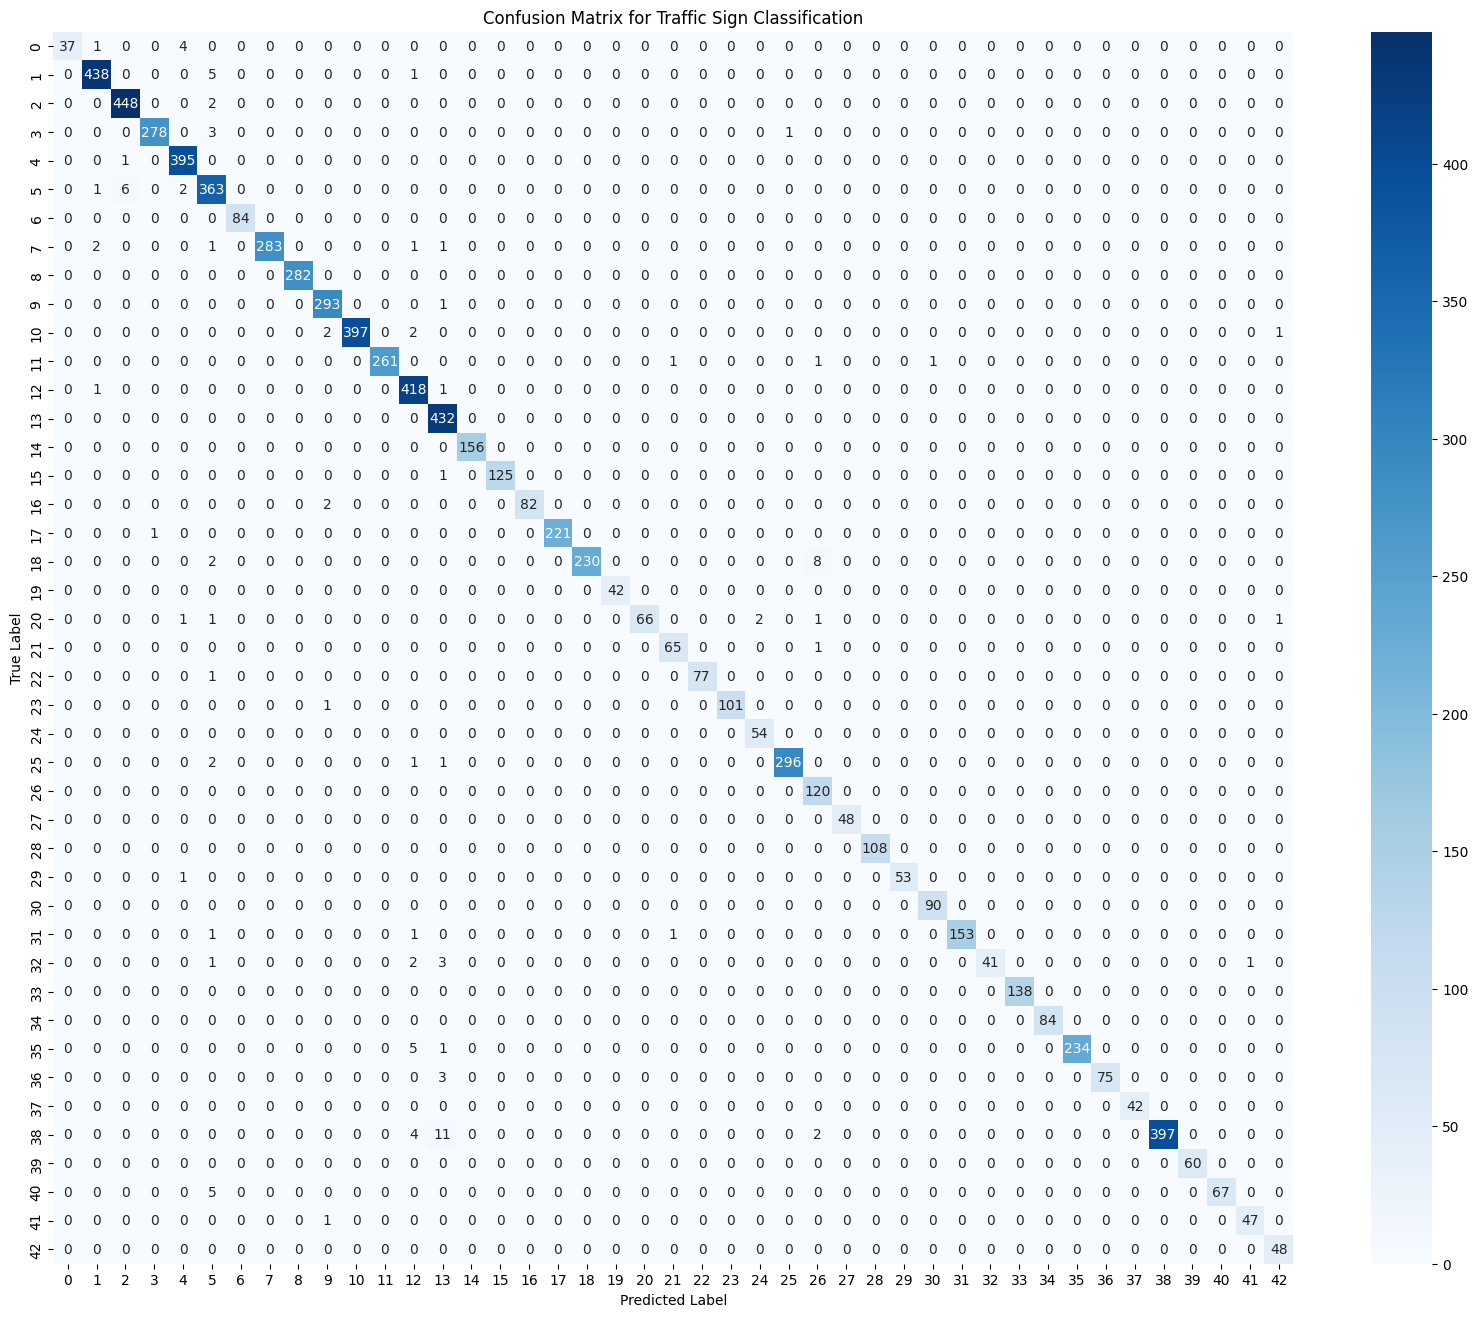

              precision    recall  f1-score   support

           0       1.00      0.88      0.94        42
           1       0.99      0.99      0.99       444
           2       0.98      1.00      0.99       450
           3       1.00      0.99      0.99       282
           4       0.98      1.00      0.99       396
           5       0.94      0.98      0.96       372
           6       1.00      1.00      1.00        84
           7       1.00      0.98      0.99       288
           8       1.00      1.00      1.00       282
           9       0.98      1.00      0.99       294
          10       1.00      0.99      0.99       402
          11       1.00      0.99      0.99       264
          12       0.96      1.00      0.98       420
          13       0.95      1.00      0.97       432
          14       1.00      1.00      1.00       156
          15       1.00      0.99      1.00       126
          16       1.00      0.98      0.99        84
          17       1.00    

In [7]:
# Predict on validation data
y_val_pred = model.predict(X_val)
y_val_pred_classes = np.argmax(y_val_pred, axis=1)
y_val_true_classes = np.argmax(y_val, axis=1)

# Generate confusion matrix
cm = confusion_matrix(y_val_true_classes, y_val_pred_classes)

# Plot Confusion Matrix
plt.figure(figsize=(20, 16))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(NUM_CLASSES), yticklabels=range(NUM_CLASSES))
plt.title('Confusion Matrix for Traffic Sign Classification')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig('confusion_matrix.png')
plt.show()

# Print classification report to see precision, recall, and F1-score per class
print(classification_report(y_val_true_classes, y_val_pred_classes))